In [2]:
%load_ext autoreload
%autoreload 2
import data.GradualePipeline as gs
from models.mm_music_components_region_mode import MelodicComponentsRegionModeModel
data_mode = gs.GradualePipeline.load("data/processed/dataset_pitches_modes.pkl")
len(data_mode['x_0_obs'])

134

In [84]:
import pymc as pm
from pymc.pytensorf import collect_default_updates
import numpy as np
import pytensor
import pytensor.tensor as pt
from models import base_model
from priors.alpha_prior import get_d2g_alpha


class MelodicComponentsRegionModeIIModel(base_model.Model):
    def __init__(self, data=None, coords=None):
        super().__init__(data=data, coords=coords)
        self.alpha = get_d2g_alpha(self.V)
        self.M = 8
        self.R = 3  # West, East, Italy

    @staticmethod
    def step_fn(t, state_tm1, transition_p, end_t):
        V = transition_p.shape[-1]
        idx = pt.clip(state_tm1, 0, V - 1)

        # Handle both single sequence (V, V) and batch mode (N, V, V)
        if transition_p.ndim == 3:
            batch_idx = pt.arange(idx.shape[0])
            p = transition_p[batch_idx, idx]
        else:
            p = transition_p[idx]

        state_t = pm.Categorical.dist(p=p)

        end_state = pm.DiracDelta.dist(-1, shape=state_t.shape)
        state_t = pt.where(t >= end_t, end_state, state_t)

        return state_t, collect_default_updates([state_t])

    @staticmethod
    def scan_dist(init_state, transition_p, end_t, size):
        states, _ = pytensor.scan(
            fn=MelodicComponentsRegionModeModel.step_fn,
            sequences=[pt.arange(end_t.max())],
            outputs_info=[init_state],
            non_sequences=[transition_p, end_t],
            strict=True,
        )
        return states

    def _setup_components(self, param_shape):

        i_idx = np.arange(self.V)[:, None]  # (V, 1)
        j_idx = np.arange(self.V)[None, :]  # (1, V)

        #base_logits = pm.Normal("base_logits", mu=0, sigma=1.0, shape=(*param_shape, self.V, self.V))

        w_interval = pm.HalfNormal("w_interval", sigma=0.5, shape=param_shape)
        w_register = pm.HalfNormal("w_register",  sigma=0.2, shape=param_shape)
        w_repeat = pm.Normal("w_repeat", mu=-0.6, sigma=0.5, shape=param_shape)
        w_direction = pm.Normal("w_direction", mu=-0.2, sigma=0.4, shape=param_shape)
        register_center = pm.Normal("register_center", mu=self.V / 4.0, sigma=self.V / 4.0, shape=param_shape)

        w_int_exp = w_interval[..., None, None]
        w_reg_exp = w_register[..., None, None]
        w_rep_exp = w_repeat[..., None, None]
        w_dir_exp = w_direction[..., None, None]
        reg_center_exp = register_center[..., None, None]

        interval_dist_sq = (i_idx - j_idx) ** 2
        pitch_dist_sq = (j_idx - reg_center_exp) ** 2  # Broadcasts to (*param_shape, 1, V)
        is_repeat = (i_idx == j_idx).astype(float)
        direction = np.sign(j_idx - i_idx).astype(float)

        logits = (
                #base_logits
                - (w_int_exp * interval_dist_sq)
                - (w_reg_exp * pitch_dist_sq)
                + (w_rep_exp * is_repeat)
                + (w_dir_exp * direction)
        )

        A = pm.Deterministic("A", pm.math.softmax(logits, axis=-1))
        return A

    def build_inference_model(self, x_0_obs, x_t_obs, lengths_obs, m_obs=None, region_obs=None, **kwargs):
        use_modes = m_obs is not None
        use_regions = region_obs is not None

        with pm.Model() as model:
            # Determine hierarchy shape
            param_shape = []
            if use_regions: param_shape.append(self.R)
            if use_modes: param_shape.append(self.M)
            param_shape = tuple(param_shape)

            A = self._setup_components(param_shape)
            pi = pm.Dirichlet("pi", a=self.alpha)

            pm.Categorical("x_0", p=pi, observed=x_0_obs)

            if use_regions and use_modes:
                nu_global = pm.Dirichlet("nu_global", a=np.ones(self.M))
                kappa = pm.Exponential("kappa", 1.0)
                nu = pm.Dirichlet("nu", a=nu_global * kappa, shape=(self.R, self.M))
                pm.Categorical("m", p=nu[region_obs], observed=m_obs)
            elif use_modes:
                nu = pm.Dirichlet("nu", a=np.ones(self.M))
                pm.Categorical("m", p=nu, observed=m_obs)

            x_0_reshaped = pt.shape_padleft(x_0_obs)
            x_full = pt.concatenate([x_0_reshaped, x_t_obs], axis=0)
            x_tm1 = x_full[:-1]
            x_t = x_full[1:]

            t_idx = pt.arange(x_t_obs.shape[0])
            mask = t_idx[:, None] < lengths_obs[None, :]

            valid_x_tm1 = x_tm1[mask]
            valid_x_t = x_t[mask]

            seq_idx = pt.arange(x_t_obs.shape[1])[None, :]
            seq_idx_broadcast = pt.alloc(seq_idx, x_tm1.shape[0], x_tm1.shape[1])
            valid_seq_idx = seq_idx_broadcast[mask]

            if use_modes:
                m_obs_pt = pt.as_tensor_variable(m_obs)
            if use_regions:
                region_obs_pt = pt.as_tensor_variable(region_obs)

            if use_regions and use_modes:
                p_valid = A[region_obs_pt[valid_seq_idx], m_obs_pt[valid_seq_idx], valid_x_tm1]
            elif use_modes:
                p_valid = A[m_obs_pt[valid_seq_idx], valid_x_tm1]
            else:
                p_valid = A[valid_x_tm1]

            pm.Categorical("transitions", p=p_valid, observed=valid_x_t)

        self.model = model
        return model

    def build_generative_model(self, m_obs=None, region_obs=None, use_modes=False, use_regions=False, **kwargs):
        with pm.Model() as model:
            param_shape = []
            if use_regions: param_shape.append(self.R)
            if use_modes: param_shape.append(self.M)
            param_shape = tuple(param_shape)

            A = self._setup_components(param_shape)
            pi = pm.Dirichlet("pi", a=self.alpha)
            if use_regions and use_modes:
                r = pt.as_tensor_variable(region_obs) if region_obs is not None else pm.Categorical("region", p=np.ones(
                    self.R) / self.R)
                m = pt.as_tensor_variable(m_obs) if m_obs is not None else pm.Categorical("m", p=
                pm.Dirichlet("nu_g", a=np.ones(self.M))[r])
                A_seq = A[r, m]
                batch_shape = r.shape
            elif use_modes:
                m = pt.as_tensor_variable(m_obs) if m_obs is not None else pm.Categorical("m", p=pm.Dirichlet("nu",
                                                                                                              a=np.ones(
                                                                                                                  self.M)))
                A_seq = A[m]
                batch_shape = m.shape
            else:
                A_seq = A
                batch_shape = None

            x_0 = pm.Categorical("x_0", p=pi, shape=batch_shape)
            length = pm.Poisson("length", self.mean_seq_len, shape=batch_shape)

            pm.CustomDist(
                "x_t+1",
                x_0,
                A_seq,
                length,
                dist=MelodicComponentsRegionModeModel.scan_dist,
            )

        self.model = model
        return model

    def build_model(self, x_0_obs=None, x_t_obs=None, lengths_obs=None, m_obs=None, region_obs=None, **kwargs):
        if x_t_obs is not None:
            return self.build_inference_model(x_0_obs, x_t_obs, lengths_obs, m_obs, region_obs, **kwargs)
        else:
           return self.build_generative_model(m_obs, region_obs, **kwargs)

In [85]:
model = MelodicComponentsRegionModeIIModel()
model.build_model()
samples = model.prior_predict(1)
[model.show_melody(s) for s in samples][0]

Sampling: [length, pi, register_center, w_direction, w_interval, w_register, w_repeat, x_0, x_t+1]


In [39]:

model = MelodicComponentsRegionModeIIModel()
trace = model.fit(data_mode, use_latest=True, draws=1000, tune=500, description="First try wo base with likelihood")

In [4]:
trace

Inference data with groups:
	> posterior
	> log_likelihood
	> sample_stats
	> observed_data

Modell ist nicht hierarchisch, Fallback wird benötigt.
Plots erfolgreich gespeichert in: /Users/timeipert/PycharmProjects/generative_medieval_music_model/visual/components_regioII


{'all_musical_weights': None,
 'detailed_regional_comparison': <Figure size 1200x1600 with 4 Axes>,
 'register_centers': <Figure size 1000x600 with 1 Axes>}

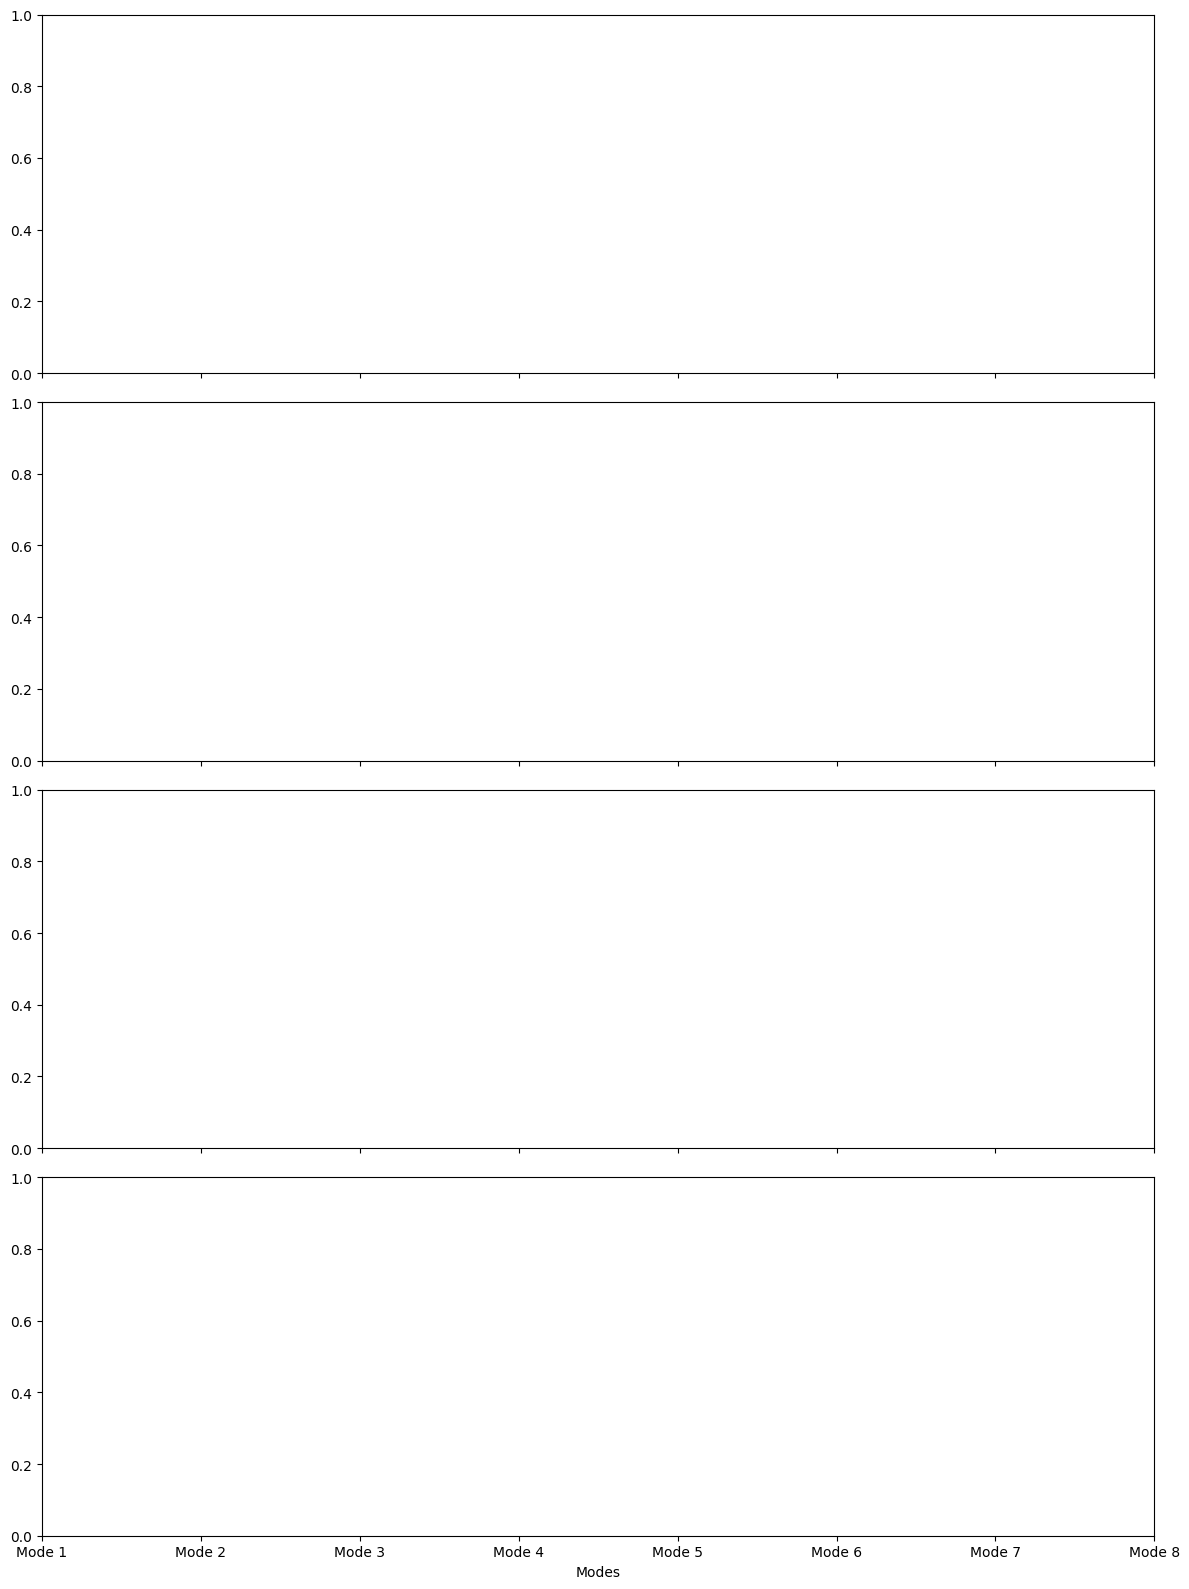

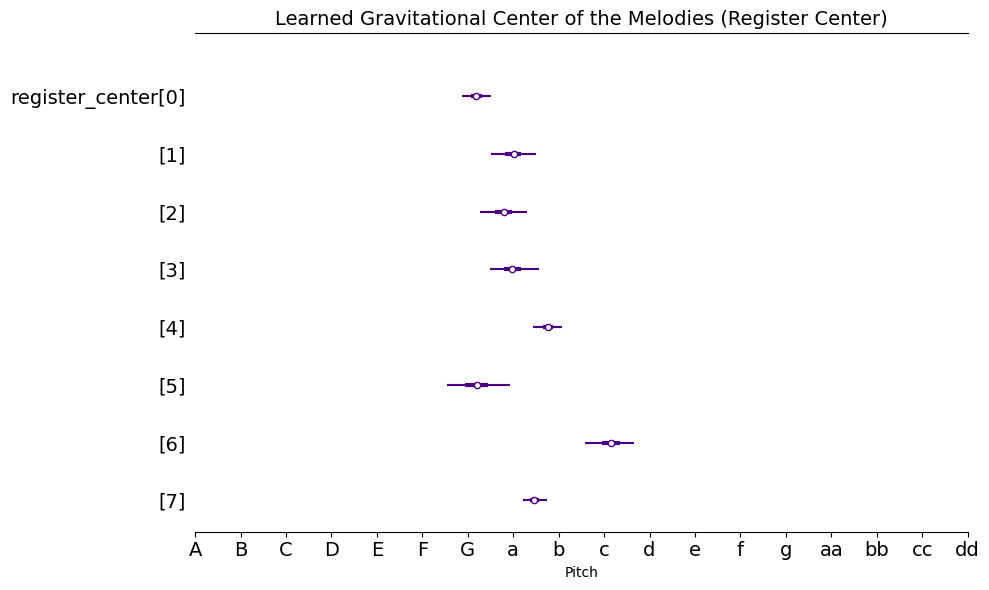

In [11]:
export_all_component_plots(trace, len(model.alphabet), group_forest_by=None)

In [4]:
data_region = gs.GradualePipeline.load("data/processed/dataset_pitches_modes_regions.pkl")

model_region = MelodicComponentsRegionModeIIModel()
trace_region = model_region.fit(data_region, use_latest=True, draws=1000, tune=500, description="First_try_region with likelihood" )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [w_interval, w_register, w_repeat, w_direction, register_center, pi, nu_global, kappa, nu]


Output()

Sampling 4 chains for 500 tune and 1_000 draw iterations (2_000 + 4_000 draws total) took 484 seconds.


In [ ]:
from analysis.vis_posterior_comp_regio import export_all_component_plots, plot_jsd_categorical_with_uncertainty

KeyError: "'region' is not a valid dimension or coordinate for Dataset with dimensions FrozenMappingWarningOnValuesAccess({'chain': 4, 'draw': 500, 'w_interval_dim_0': 3, 'w_interval_dim_1': 8})"

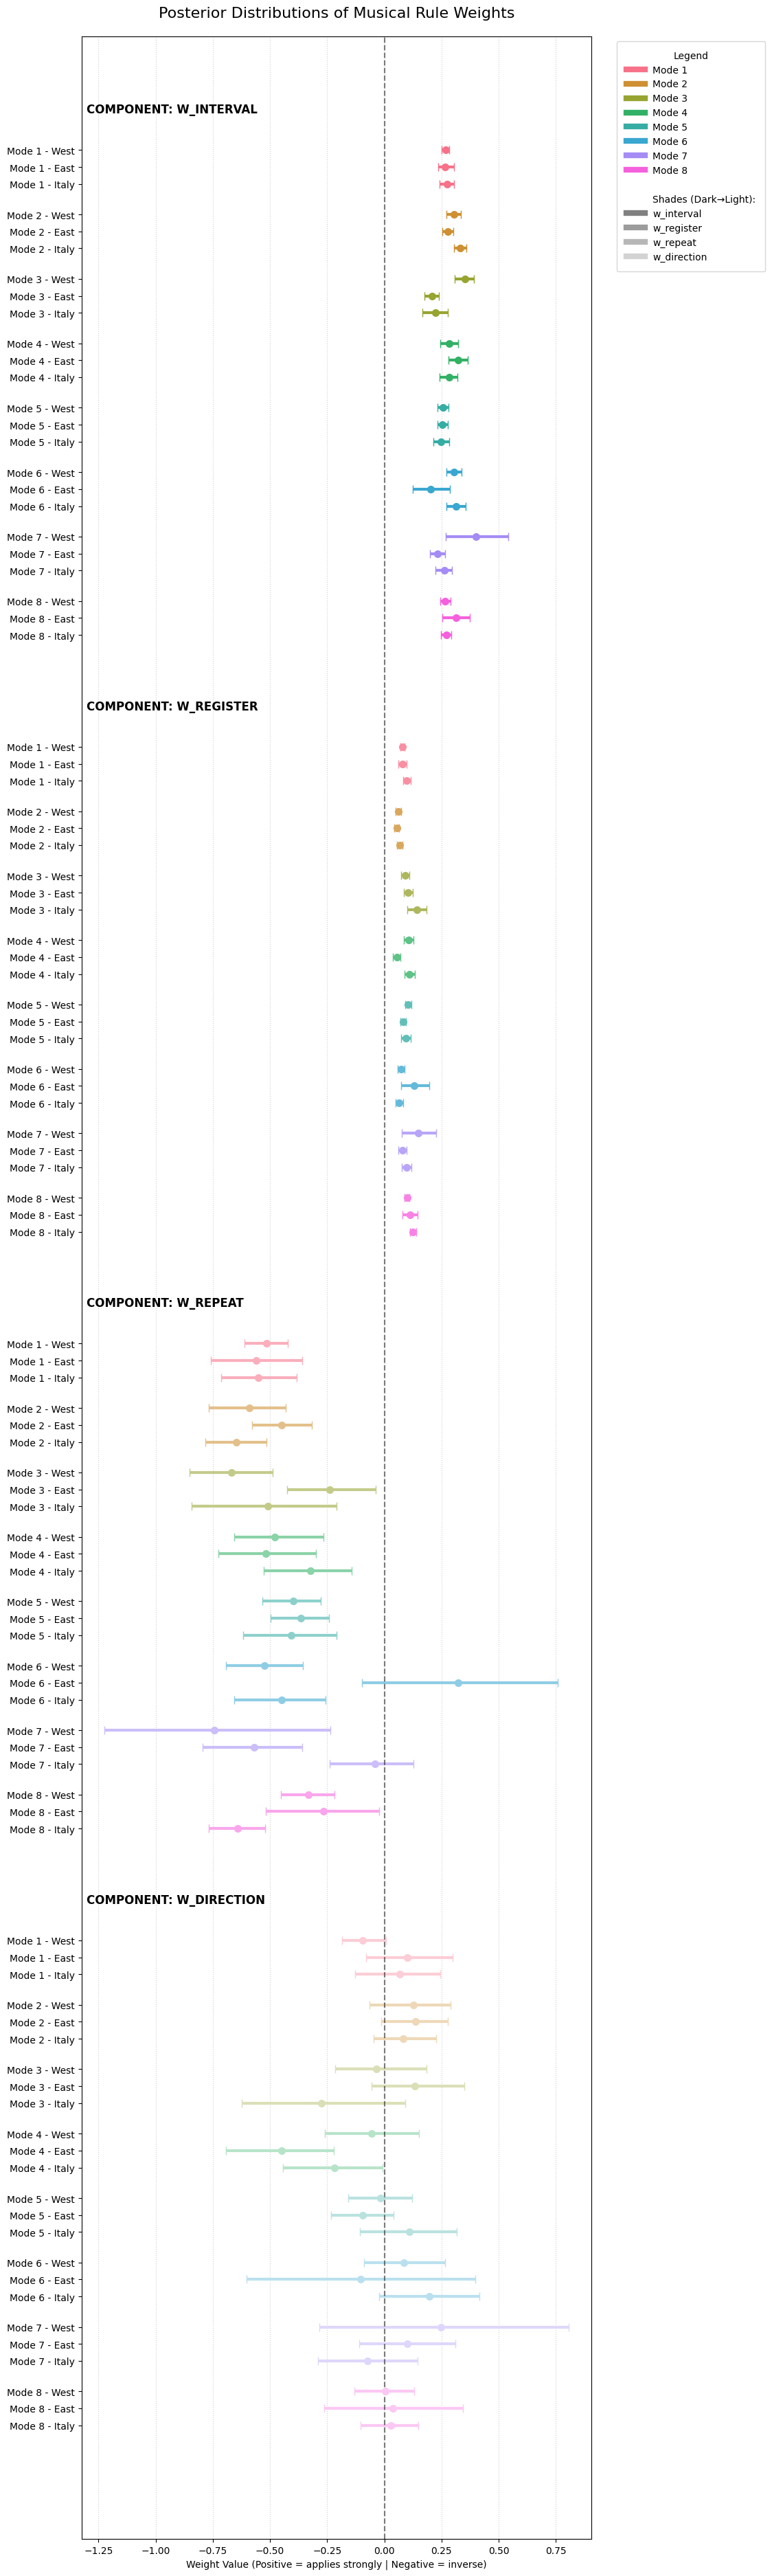

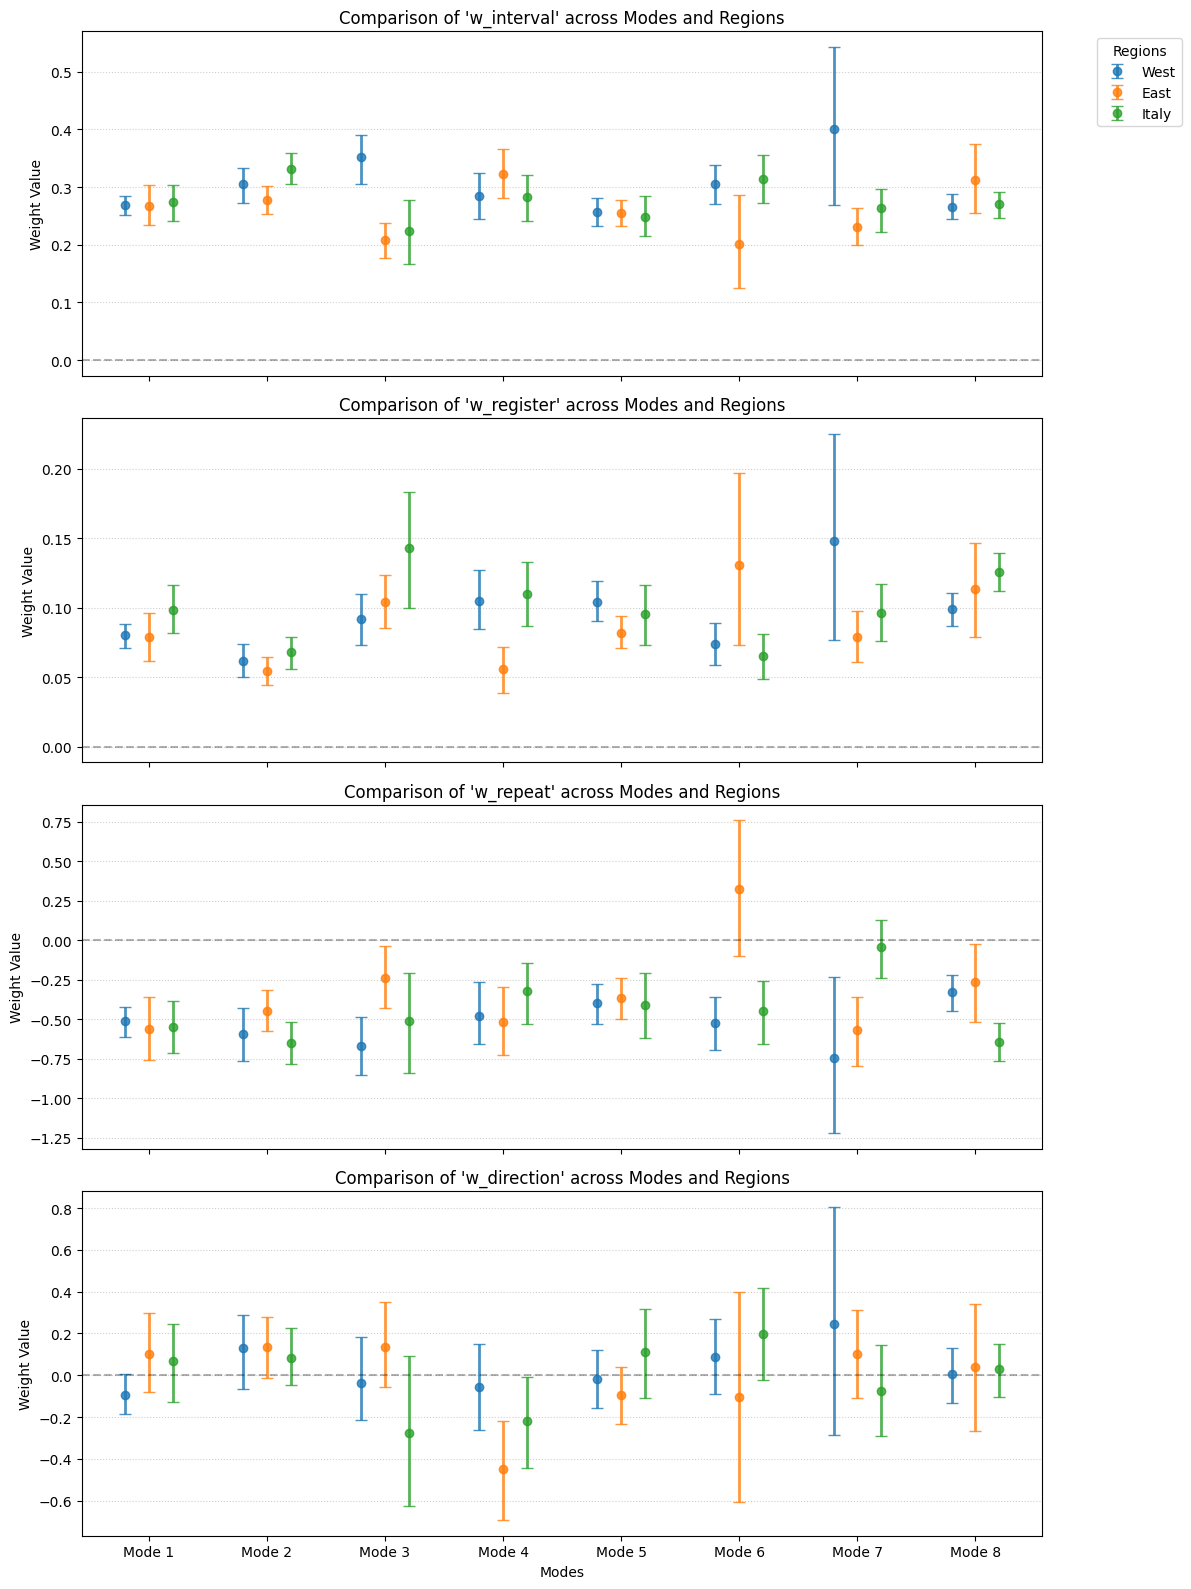

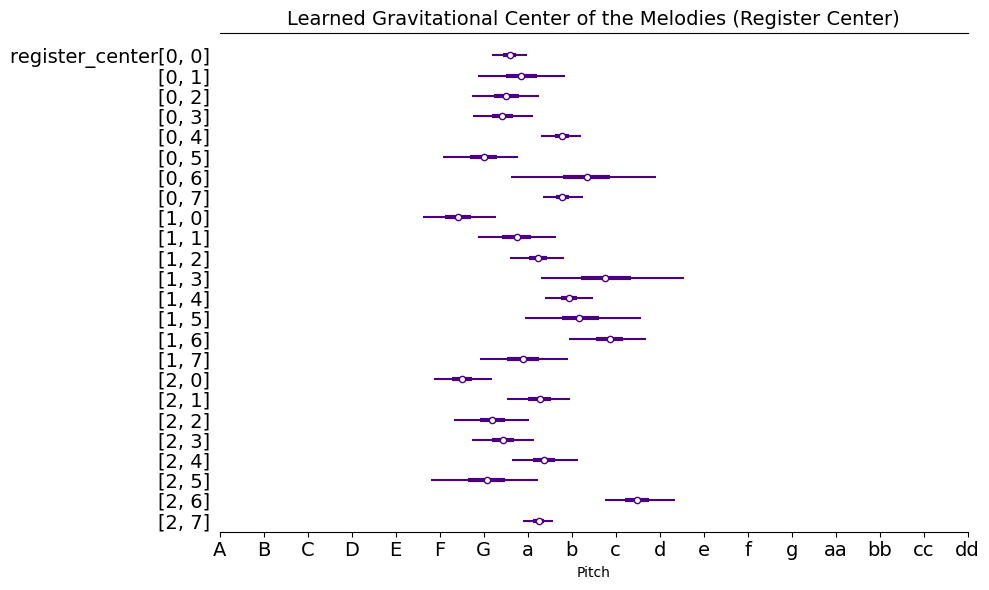

In [8]:
export_all_component_plots(trace_region, len(model_region.alphabet), save_dir="visual/components_regionII/")

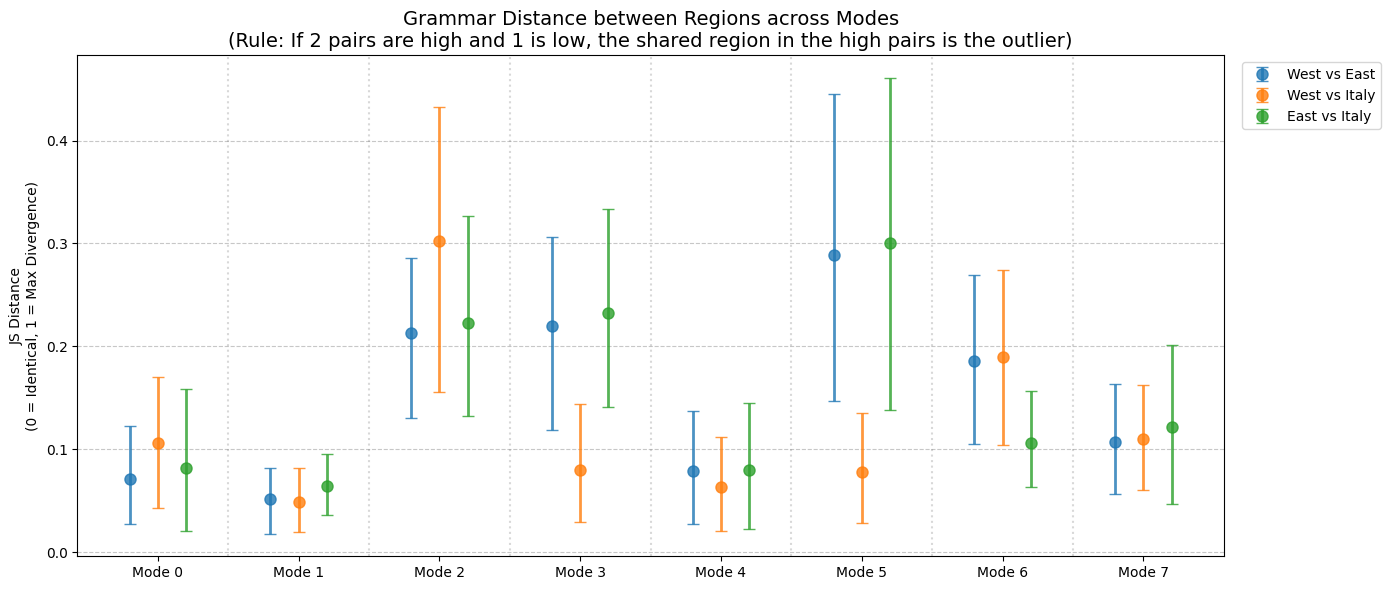

In [9]:

fig1 = plot_jsd_categorical_with_uncertainty(trace_region, r_labels=["West", "East", "Italy"])

In [14]:
trace

Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

In [91]:
import arviz as az
comparison = az.compare({"mode": trace, "region": trace_region}, var_name="transitions",)

In [92]:
comparison

,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
region,0,-34551.170544,119.420149,0.000000,1.000000e+00,98.494528,0.000000,False,log
mode,1,-34603.001692,39.518572,51.831148,3.090428e-23,97.309004,16.642568,False,log


<Axes: title={'center': 'Model comparison\nhigher is better'}, xlabel='elpd_loo (log)', ylabel='ranked models'>

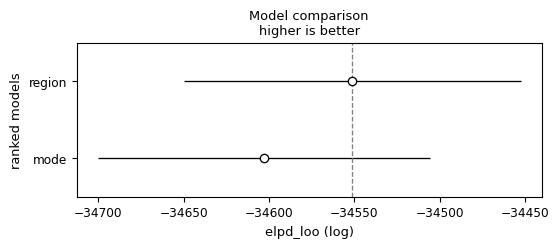

In [93]:
az.plot_compare(comparison)